Tieu Han TRAN - M2 MIAGE

# Statistical and Machine Learning
# Homework 2 : Uniform Convergence and the Limits of Learning

# Part I – Simulating Uniform Convergence

## Problème étudié
* Classe d'hypothèses finie : $\mathcal{H} = \{h_1, \dots, h_K\}$ de taille $\vert{}\mathcal{H}\vert{} = K < \infty$.
* True risk (erreur vraie) : Chaque hypothèse $h_j$ possède une erreur vraie fixée $L_\mathcal{D}(h_j) = p_j \in [0, 1]$.
* Nombre d'erreurs sur le training sample : Chaque exemple est mal classé par $h_j$ avec une probabilité $p_j$ (variable de Bernoulli de paramètre $p_j$). Le nombre total d'erreurs $E_j$ commises par $h_j$ sur les $m$ exemples suit donc une loi Binomiale :
$$E_j \sim \text{Binomial}(m, p_j)$$
* Empirical risk (erreur empirique) : C'est la proportion d'erreurs commises sur le training sample de taille $m$ :
$$L_S(h_j) = \frac{E_j}{m}$$

## 1. Empirical Risk as a Random Variable

Dans cette première question, on étudie le comportement de l'empirical error $L_S(h_j) = \frac{E_j}{m}$ en tant que variable aléatoire qui est autour du true error $L_\mathcal{D}(h_j) = p_j$.

### Choix et justification des paramètres expérimentaux :
* True errors des hypothèses ($p_1, \dots, p_K$) : On choisit $K = 5$ hypothèses ayant des true errors variés `p_tab = [0.05, 0.15, 0.25, 0.40, 0.70]` (allant d'une très bonne hypothèse qui se trompe $5\%$ du temps à une hypothèse qui fait du hasard à $70\%$). Pour l'étude détaillée sur une hypothèse fixée $h_j$, on sélectionne $p_j = 0.25$ car cette valeur permet d'observer une distribution bien symétrique sans être trop proche de 0 ou de 1.
* Tailles d'échantillon ($m$) : On choisit `m_tab = [10, 30, 50, 100, 250, 500, 1000]`. Ces tailles sont suffisamment variées pour observer la transition entre de très petits échantillons et de grands échantillons.
* Nombre de répétitions de Monte-Carlo : On fixe `N_REPETITIONS = 5000` tirages indépendants pour chaque taille $m$ afin que nos moyennes empiriques et nos histogrammes soient très précis.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Fixer le point de départ (seed) pour reproduire les expériences et avoir les mêmes résultats pour les interprétations
np.random.seed(0)

# Paramètres globaux pour la Partie I (Task 1)
# True errors p_1, ..., p_K choisies pour différentes hypothèses
p_tab = [
    0.05,
    0.15,
    0.25,
    0.40,
    0.70,
]

# Vraie erreur L_D(h_j) = p_j de l'hypothèse fixée h_j pour l'analyse
P_FIXE = (
    0.25  
)

# Différentes tailles du training sample m
m_tab = [
    10,
    30,
    50,
    100,
    250,
    500,
    1000,
]

# Nombre de répétitions de Monte-Carlo
N_REPETITIONS = 5000


def simuler_risque_empirique(m, p_j, n_rep=N_REPETITIONS):
  """Simule le risque empirique L_S(h_j) = E_j / m sur n_rep training samples de taille m.

  Entrées :
  - m (int) : Taille du training sample S.
  - p_j (float) : True risk L_D(h_j) de l'hypothèse h_j dans [0,1].
  - n_rep (int) : Nombre de simulations de Monte-Carlo.
  Retourne :
  - ls_tab (np.ndarray) : Tableau 1D de taille n_rep contenant les risques empiriques L_S(h_j) simulés.
  """
  # (a) Simulation du nombre d'erreurs E_j selon une loi Binomiale(m, p_j) répété n_rep fois
  ej_tab = np.random.binomial(n=m, p=p_j, size=n_rep)

  # (b) Calcul du risque empirique L_S(h_j) = E_j / m pour chaque répétition
  ls_tab = ej_tab / m
  return ls_tab


# Exécution des simulations pour l'hypothèse fixée (p_j = 0.25) pour chaque taille m
resultats_q1 = {}
print(
    f"Comparaison Moyenne Empirique vs Vrai Risque (p_j = {P_FIXE},"
    f" {N_REPETITIONS} répétitions) :\n"
)

for m in m_tab:
  ls_simules = simuler_risque_empirique(m, P_FIXE, N_REPETITIONS)
  moyenne_emp = np.mean(ls_simules)
  ecart_type_emp = np.std(ls_simules)
  # L'écart-type théorique d'une moyenne de Bernoulli est sqrt(p_j * (1 - p_j) / m)
  ecart_type_theo = np.sqrt(P_FIXE * (1.0 - P_FIXE) / m)

  resultats_q1[m] = (ls_simules, moyenne_emp, ecart_type_emp, ecart_type_theo)

  print(
      f"m = {m:4d} | Moyenne de L_S(h_j) = {moyenne_emp:.4f} (Vrai p_j ="
      f" {P_FIXE:.4f}) | Écart-type exp = {ecart_type_emp:.4f} (Théorique ="
      f" {ecart_type_theo:.4f})"
  )

# Vérification rapide sur les autres valeurs de p_1, ..., p_K pour m = 100
print(
    "\nVérification de l'espérance E[L_S(h_k)] = p_k pour les autres hypothèses"
    " (avec m = 100) :"
)
for idx, p_k in enumerate(p_tab):
  moy_k = np.mean(simuler_risque_empirique(100, p_k, N_REPETITIONS))
  print(
      f"Hypothèse h_{idx+1} : Vrai risque p_{idx+1} = {p_k:.2f} | Moyenne"
      f" empirique observée = {moy_k:.4f}"
  )

Comparaison Moyenne Empirique vs Vrai Risque (p_j = 0.25, 5000 répétitions) :

m =   10 | Moyenne de L_S(h_j) = 0.2493 (Vrai p_j = 0.2500) | Écart-type exp = 0.1370 (Théorique = 0.1369)
m =   30 | Moyenne de L_S(h_j) = 0.2486 (Vrai p_j = 0.2500) | Écart-type exp = 0.0795 (Théorique = 0.0791)
m =   50 | Moyenne de L_S(h_j) = 0.2480 (Vrai p_j = 0.2500) | Écart-type exp = 0.0609 (Théorique = 0.0612)
m =  100 | Moyenne de L_S(h_j) = 0.2501 (Vrai p_j = 0.2500) | Écart-type exp = 0.0446 (Théorique = 0.0433)
m =  250 | Moyenne de L_S(h_j) = 0.2491 (Vrai p_j = 0.2500) | Écart-type exp = 0.0271 (Théorique = 0.0274)
m =  500 | Moyenne de L_S(h_j) = 0.2498 (Vrai p_j = 0.2500) | Écart-type exp = 0.0194 (Théorique = 0.0194)
m = 1000 | Moyenne de L_S(h_j) = 0.2501 (Vrai p_j = 0.2500) | Écart-type exp = 0.0135 (Théorique = 0.0137)

Vérification de l'espérance E[L_S(h_k)] = p_k pour les autres hypothèses (avec m = 100) :
Hypothèse h_1 : Vrai risque p_1 = 0.05 | Moyenne empirique observée = 0.0499
Hypo

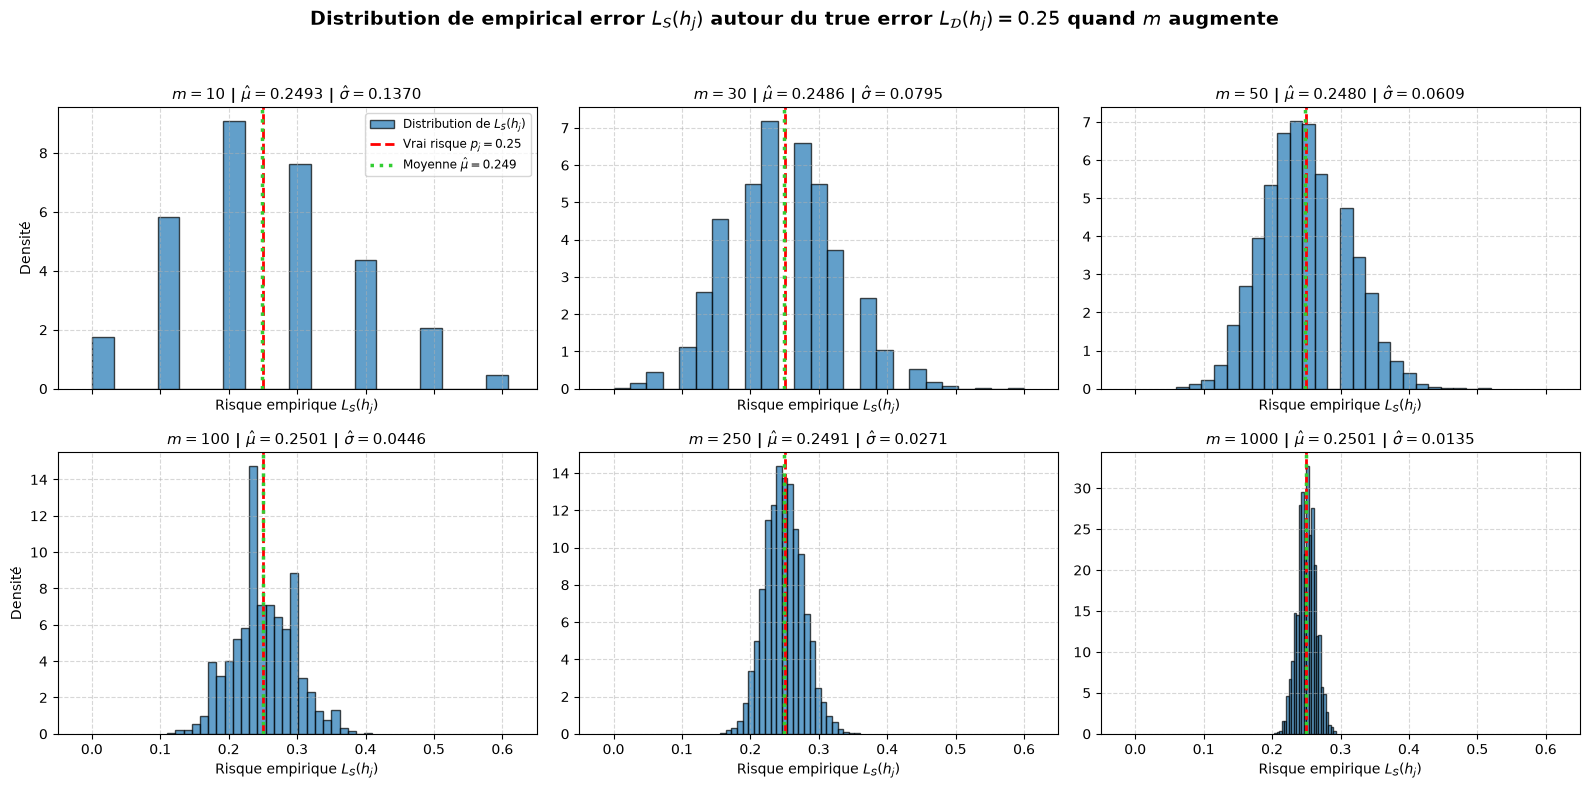

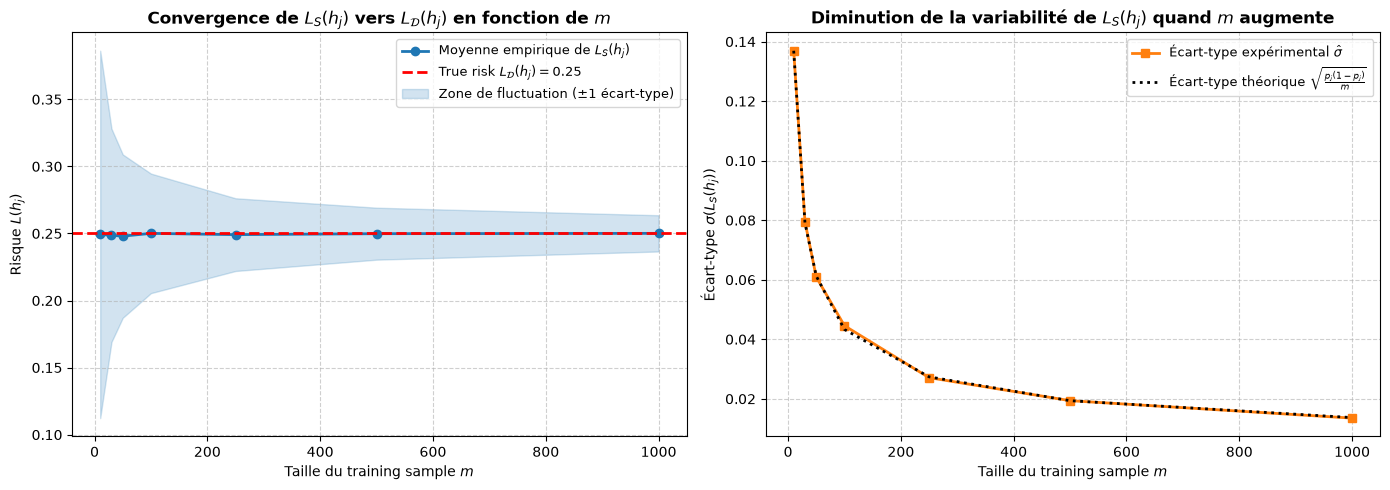

In [2]:
# (c) & (d) Visualisation 1 : Distribution de L_S(h_j) pour plusieurs tailles d'échantillon m
m_visu = [10, 30, 50, 100, 250, 1000]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
axes = axes.flatten()

for idx, m in enumerate(m_visu):
  ax = axes[idx]
  ls_simules, moy_emp, std_emp, _ = resultats_q1[m]

  # Histogramme de la distribution des risques empiriques L_S(h_j)
  ax.hist(
      ls_simules,
      bins=25,
      density=True,
      color='tab:blue',
      alpha=0.7,
      edgecolor='black',
      label=r'Distribution de $L_S(h_j)$',
  )

  # Ligne verticale rouge : Vrai risque L_D(h_j) = p_j
  ax.axvline(
      x=P_FIXE,
      color='red',
      linestyle='--',
      linewidth=2,
      label=rf'Vrai risque $p_j = {P_FIXE}$',
  )

  # Ligne verticale verte : Moyenne empirique sur les 5000 simulations
  ax.axvline(
      x=moy_emp,
      color='limegreen',
      linestyle=':',
      linewidth=2.5,
      label=rf'Moyenne $\hat{{\mu}} = {moy_emp:.3f}$',
  )

  ax.set_title(
      rf'$m = {m}$ | $\hat{{\mu}} = {moy_emp:.4f}$ | $\hat{{\sigma}} ='
      rf' {std_emp:.4f}$',
      fontsize=11,
      fontweight='bold',
  )
  ax.set_xlabel(r'Risque empirique $L_S(h_j)$')
  if idx % 3 == 0:
    ax.set_ylabel('Densité')
  ax.set_xlim(-0.05, 0.65)
  ax.grid(True, linestyle='--', alpha=0.5)

  if idx == 0:
    ax.legend(loc='upper right', fontsize=8.5)

plt.suptitle(
    rf'Distribution de empirical error $L_S(h_j)$ autour du true error $L_\mathcal{{D}}(h_j) = {P_FIXE}$ quand $m$ augmente',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Visualisation 2 : Évolution de la moyenne empirique et de l'écart-type (variabilité) en fonction de m
moyennes_tab = [resultats_q1[m][1] for m in m_tab]
std_exp_tab = [resultats_q1[m][2] for m in m_tab]
std_theo_tab = [resultats_q1[m][3] for m in m_tab]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graphique de gauche : Moyenne empirique avec bande de +/- 1 écart-type
ax1.plot(
    m_tab,
    moyennes_tab,
    marker='o',
    color='tab:blue',
    linewidth=2,
    label=r'Moyenne empirique de $L_S(h_j)$',
)
ax1.axhline(
    y=P_FIXE,
    color='red',
    linestyle='--',
    linewidth=2,
    label=rf'True risk $L_\mathcal{{D}}(h_j) = {P_FIXE}$',
)
ax1.fill_between(
    m_tab,
    np.array(moyennes_tab) - np.array(std_exp_tab),
    np.array(moyennes_tab) + np.array(std_exp_tab),
    color='tab:blue',
    alpha=0.2,
    label=r'Zone de fluctuation ($\pm 1$ écart-type)',
)
ax1.set_title(
    r'Convergence de $L_S(h_j)$ vers $L_\mathcal{D}(h_j)$ en fonction de $m$',
    fontsize=12,
    fontweight='bold',
)
ax1.set_xlabel(r'Taille du training sample $m$')
ax1.set_ylabel(r'Risque $L(h_j)$')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=9.5)

# Graphique de droite : Diminution de l'écart-type (variabilité) avec m
ax2.plot(
    m_tab,
    std_exp_tab,
    marker='s',
    color='tab:orange',
    linewidth=2,
    label=r'Écart-type expérimental $\hat{\sigma}$',
)
ax2.plot(
    m_tab,
    std_theo_tab,
    linestyle=':',
    color='black',
    linewidth=2,
    label=r'Écart-type théorique $\sqrt{\frac{p_j(1-p_j)}{m}}$',
)
ax2.set_title(
    r'Diminution de la variabilité de $L_S(h_j)$ quand $m$ augmente',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel(r'Taille du training sample $m$')
ax2.set_ylabel(r'Écart-type $\sigma(L_S(h_j))$')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=9.5)

plt.tight_layout()
plt.show()

### Interprétation de la Question 1 : Empirical Risk as a Random Variable

**1. Comparaison entre la moyenne empirique et le vrai risque (estimateur sans biais) :**
   * On observe que pour toutes les tailles d'échantillons $m \in \{10, \dots, 1000\}$ (et pour toutes les valeurs de $p_k$ testées), la moyenne empirique des risques $\hat{\mu}$ (ligne verticale verte en pointillés) est quasiment confondue avec le vrai risque $L_\mathcal{D}(h_j) = p_j = 0.25$ (ligne verticale rouge).
   * Cela vérifie expérimentalement la propriété démontrée dans l'exercice 2 du TD1 : l'erreur empirique est une moyenne de variables aléatoires i.i.d. $\theta_i = \mathbb{1}\{h_j(x_i) \neq y_i\}$ d'espérance $\mathbb{E}[\theta_i] = L_\mathcal{D}(h_j) = p_j$. On a donc :
   $$\mathbb{E}_{S \sim \mathcal{D}^m}[L_S(h_j)] = \frac{1}{m}\sum_{i=1}^m \mathbb{E}[\theta_i] = L_\mathcal{D}(h_j) = p_j$$
   Le risque empirique $L_S(h_j)$ est donc un estimateur sans biais du true risk $L_\mathcal{D}(h_j)$, c'est-à-dire à force de répéter plusieurs fois l'expérience et en calculant l'empirical error, la moyenne des empirical error finit par donner le true risk.

**2. Évolution de la variabilité de $L_S(h_j)$ lorsque $m$ augmente :**
   * Pour un petit échantillon ($m = 10$ ou $m = 30$) : L'histogramme est très étalé (de $0.0$ jusqu'à $0.6$). L'écart-type vaut $\hat{\sigma} \approx 0.136$ pour $m=10$. Cela signifie que sur un seul tirage d'entraînement de petite taille, le risque empirique $L_S(h_j)$ peut facilement valoir proche de $0.0$ ou de $0.5$ par pur hasard, donnant une très mauvaise estimation du vrai risque $p_j = 0.25$.
   * Lorsque $m$ augmente ($m = 250, 500, 1000$) : L'histogramme se resserre de plus en plus en forme de cloche étroite autour de la valeur cible $p_j = 0.25$. Pour $m = 1000$, l'écart-type descend à $\hat{\sigma} \approx 0.0137$.
   * Explication théorique : Comme $E_j \sim \text{Binomial}(m, p_j)$ a pour variance $\text{Var}(E_j) = m p_j(1 - p_j)$, la variance de $L_S(h_j) = \frac{E_j}{m}$ vaut :
   $$\text{Var}(L_S(h_j)) = \frac{p_j(1 - p_j)}{m} \quad \implies \quad \sigma(L_S(h_j)) = \sqrt{\frac{p_j(1 - p_j)}{m}}$$
   Sur le deuxième graphique, la courbe expérimentale orange suit parfaitement la courbe théorique en $\frac{1}{\sqrt{m}}$. Conformément à la Loi des Grands Nombres, plus la taille d'échantillon $m$ augmente, plus la variance tend vers $0$ et plus le risque empirique $L_S(h_j)$ se rapproche du vrai risque $L_\mathcal{D}$.

## 2. Deviation Between Empirical and True Risk

Pour une hypothèse fixée $h_j$, on s'intéresse maintenant au Generalization Gap :
$$\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{}$$

Estimer expérimentalement la probabilité que cet écart dépasse un seuil de tolérance $\epsilon > 0$ (c'est-à-dire la probabilité que l'échantillon $S$ donne une mauvaise approximation du vrai risque de $h_j$) :
$$\Pr\left[\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{} > \epsilon\right]$$

D'après l'inégalité de Hoeffding, comme $L_S(h_j) = \frac{1}{m}\sum_{i=1}^m \theta_i$ est la moyenne de $m$ variables aléatoires indépendantes $\theta_i \in [0, 1]$ d'espérance $\mu = L_\mathcal{D}(h_j) = p_j$, cette probabilité est bornée supérieurement par :
$$\Pr\left[\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{} > \epsilon\right] \le 2 e^{-2 m \epsilon^2}$$

### Choix des paramètres :
* On fixe le seuil de précision à **$\epsilon = 0.05$** (on tolère un écart maximal de $5\%$ entre le risque empirique et le vrai risque).
* On garde l'hypothèse fixée avec $p_j = 0.25$ (et on affiche également sur le graphique le cas $p_k = 0.05$ et $p_k = 0.40$ de notre liste `p_tab = [0.05, 0.15, 0.25, 0.40, 0.70]` pour montrer l'influence de $p_j$ par rapport à la borne de Hoeffding).

Comparaison Probabilité expérimentale (p_j = 0.25) vs Borne de Hoeffding (epsilon = 0.05) :

m =   10 | Pr_exp(|L_S - L_D| > 0.05) = 0.4654 | Borne de Hoeffding = 1.9025
m =   30 | Pr_exp(|L_S - L_D| > 0.05) = 0.4056 | Borne de Hoeffding = 1.7214
m =   50 | Pr_exp(|L_S - L_D| > 0.05) = 0.3294 | Borne de Hoeffding = 1.5576
m =  100 | Pr_exp(|L_S - L_D| > 0.05) = 0.2198 | Borne de Hoeffding = 1.2131
m =  250 | Pr_exp(|L_S - L_D| > 0.05) = 0.0536 | Borne de Hoeffding = 0.5730
m =  500 | Pr_exp(|L_S - L_D| > 0.05) = 0.0080 | Borne de Hoeffding = 0.1642
m = 1000 | Pr_exp(|L_S - L_D| > 0.05) = 0.0000 | Borne de Hoeffding = 0.0135


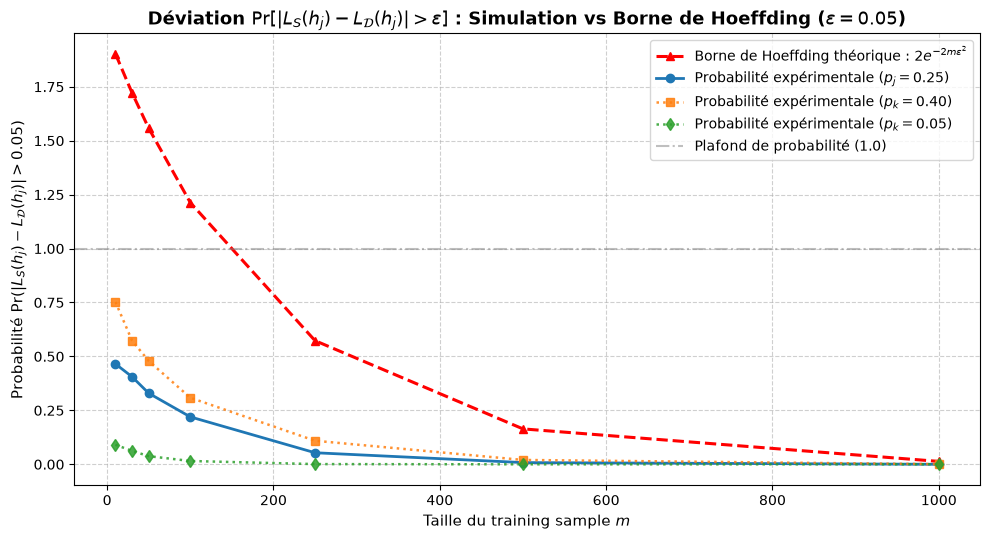

In [3]:
# Paramètre de précision epsilon choisi
EPSILON = 0.05  # Écart maximal toléré entre L_S(h_j) et L_D(h_j)

# On réutilise nos valeurs pour bien voir la décroissance exponentielle
proba_ecart_exp = (
    []
)  # Probabilité expérimentale Pr(|L_S(h_j) - L_D(h_j)| > epsilon) pour p_j = 0.25
borne_hoeffding_tab = []  # Borne théorique de Hoeffding : 2 * exp(-2 * m * epsilon^2)

print(
    f"Comparaison Probabilité expérimentale (p_j = {P_FIXE}) vs Borne de"
    f" Hoeffding (epsilon = {EPSILON}) :\n"
)

for m in m_tab:
  # Récupération des risques empiriques simulés à la Question 1 pour p_j = 0.25
  ls_simules = resultats_q1[m][0]

  # 1. Calcul de l'écart absolu |L_S(h_j) - L_D(h_j)| pour chaque sample simulé
  ecarts_absolus = np.abs(ls_simules - P_FIXE)

  # 2. Estimation de Pr(|L_S(h_j) - L_D(h_j)| > epsilon) : proportion des répétitions où l'écart dépasse epsilon
  proba_exp = np.mean(ecarts_absolus > EPSILON)
  proba_ecart_exp.append(proba_exp)

  # 3. Calcul de la borne théorique de Hoeffding : 2 * exp(-2 * m * epsilon^2)
  borne_theo = 2.0 * np.exp(-2.0 * m * (EPSILON**2))
  borne_hoeffding_tab.append(borne_theo)

  print(
      f"m = {m:4d} | Pr_exp(|L_S - L_D| > {EPSILON}) = {proba_exp:.4f} | Borne"
      f" de Hoeffding = {borne_theo:.4f}"
  )

# Calcul supplémentaire pour p = 0.05 et p = 0.40 afin d'enrichir la comparaison visuelle

proba_exp_p005 = []
proba_exp_p040 = []

for m in m_tab:

  # 1. Pour l'hypothèse avec un vrai risque de 0.05
  # Simulation de 5000 risques empiriques (L_S) pour cette taille m
  risques_simules_005 = simuler_risque_empirique(m, 0.05, N_REPETITIONS)
  # Calcul de l'écart absolu entre chaque risque simulé et le vrai risque (0.05)
  ecarts_005 = np.abs(risques_simules_005 - 0.05)
  # Calcul de la proportion que ces écarts dépasse notre seuil de tolérance (EPSILON)
  proportion_echec_005 = np.mean(ecarts_005 > EPSILON)
  # Ajout
  proba_exp_p005.append(proportion_echec_005)

  # 2. Pour l'hypothèse avec un vrai risque de 0.40
  risques_simules_040 = simuler_risque_empirique(m, 0.40, N_REPETITIONS)
  ecarts_040 = np.abs(risques_simules_040 - 0.40)
  proportion_echec_040 = np.mean(ecarts_040 > EPSILON)
  proba_exp_p040.append(proportion_echec_040)

# Visualisation : Probabilité expérimentale vs Borne de Hoeffding en fonction de m
plt.figure(figsize=(10, 5.5))

# Tracé de la borne théorique de Hoeffding
plt.plot(
    m_tab,
    borne_hoeffding_tab,
    marker="^",
    linestyle="--",
    color="red",
    linewidth=2.2,
    label=r"Borne de Hoeffding théorique : $2e^{-2m\epsilon^2}$",
)

# Tracé des probabilités expérimentales
plt.plot(
    m_tab,
    proba_ecart_exp,
    marker="o",
    linestyle="-",
    color="tab:blue",
    linewidth=2,
    label=rf"Probabilité expérimentale ($p_j = {P_FIXE}$)",
)
plt.plot(
    m_tab,
    proba_exp_p040,
    marker="s",
    linestyle=":",
    color="tab:orange",
    linewidth=1.8,
    alpha=0.85,
    label=r"Probabilité expérimentale ($p_k = 0.40$)",
)
plt.plot(
    m_tab,
    proba_exp_p005,
    marker="d",
    linestyle=":",
    color="tab:green",
    linewidth=1.8,
    alpha=0.85,
    label=r"Probabilité expérimentale ($p_k = 0.05$)",
)

# Ligne horizontale à 1.0 (probabilité maximale possible)
plt.axhline(
    y=1.0,
    color="gray",
    linestyle="-.",
    alpha=0.5,
    label="Plafond de probabilité (1.0)",
)

plt.title(
    r"Déviation $\Pr[|L_S(h_j) - L_\mathcal{D}(h_j)| > \epsilon]$ : Simulation"
    rf" vs Borne de Hoeffding ($\epsilon = {EPSILON}$)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(r"Taille du training sample $m$", fontsize=11)
plt.ylabel(
    rf"Probabilité $\Pr(|L_S(h_j) - L_\mathcal{{D}}(h_j)| > {EPSILON})$",
    fontsize=11,
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Interprétation de la Question 2 : Deviation Between Empirical and True Risk

**1. Évolution en fonction de $m$ (Décroissance exponentielle) :**
   * Aussi bien pour la courbe expérimentale que pour la courbe théorique de Hoeffding, la probabilité que le risque empirique $L_S(h_j)$ s'écarte du vrai risque $L_\mathcal{D}(h_j)$ de plus de $\epsilon = 0.05$ diminue très vite lorsque la taille de l'échantillon $m$ augmente.
   * Pour $p_j = 0.25$, la probabilité expérimentale passe de $0.4654$ (pour $m=10$) à $0.2198$ (pour $m=100$), puis tombe à $0.0000$ (pour $m=1000$). À partir de $m=1000$, il devient presque impossible que l'erreur empirique se trompe de plus de $5\%$ sur la vraie performance de l'hypothèse.

**2. La borne théorique de Hoeffding est-elle exacte ou conservatrice (conservative) ?**
   * La borne de Hoeffding est clairement conservatrice (pessimiste / large). Sur le graphique, la courbe rouge théorique $2e^{-2m\epsilon^2}$ est systématiquement située bien au-dessus des courbes expérimentales bleue, orange et verte.
   * Pourquoi est-elle aussi conservatrice ? On peut donner deux raisons :
     1. Indépendance vis-à-vis du vrai risque $p_j$ : La formule de Hoeffding $2e^{-2m\epsilon^2}$ utilise uniquement le fait que la fonction de coût est bornée dans $[a, b] = [0, 1]$. Elle ne dépend pas de $p_j$ et doit donc être valide dans le "pire des cas".
     2. Dépassement de $1$ pour les petits $m$ : Pour de petits échantillons ($m = 10, 30, 50$), la borne $2e^{-2m\epsilon^2}$ donne des valeurs supérieures à $1$ (par exemple $1.9025$ pour $m=10$ et $1.2131$ pour $m=100$ à cause du facteur $2$ devant l'exponentielle), alors qu'une probabilité ne peut jamais dépasser $1$.

## 3. From One Hypothesis to Uniform Convergence

Dans les questions précédentes, on a regardé l'écart $\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{}$ pour une *seule* hypothèse fixée $h_j$. 
Mais pour l'algorithme d'apprentissage ERM, on a besoin que cette approximation soit valable simultanément pour toutes les hypothèses de la classe $\mathcal{H} = \{h_1, \dots, h_K\}$. 

On définit donc la déviation maximale (maximum deviation) sur toute la classe d'hypothèses $\mathcal{H}$ pour un échantillon donné $S$ :
$$\Delta_S = \max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{}$$

On souhaite estimer expérimentalement la probabilité de l'événement de convergence uniforme :
$$\Pr[\Delta_S > \epsilon] = \Pr\left[\max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{} > \epsilon\right]$$

D'après le cours, la borne de convergence uniforme pour une classe d'hypothèses finie est donnée par :
$$\Pr\left[\max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{} > \epsilon\right] \le 2 \vert{}\mathcal{H}\vert{} e^{-2 m \epsilon^2}$$

### Paramètres de l'expérience :
* Taille de la classe d'hypothèses : On fixe pour l'instant $\vert{}\mathcal{H}\vert{} = K = 10$ hypothèses, dont les vrais risques $p_1, \dots, p_K$ sont répartis uniformément entre $0.05$ et $0.70$.
* Précision voulue : On garde $\epsilon = 0.05$.
* Répétitions : `N_REPETITIONS = 5000`.

Simulation de l'Uniform Convergence (|H| = 10, epsilon = 0.05, 5000 répétitions) :

m =   10 | Pr_exp(max |L_S - L_D| > 0.05) = 1.0000 | Borne UC Théo = 19.0246
m =   30 | Pr_exp(max |L_S - L_D| > 0.05) = 0.9996 | Borne UC Théo = 17.2142
m =   50 | Pr_exp(max |L_S - L_D| > 0.05) = 0.9942 | Borne UC Théo = 15.5760
m =  100 | Pr_exp(max |L_S - L_D| > 0.05) = 0.9458 | Borne UC Théo = 12.1306
m =  250 | Pr_exp(max |L_S - L_D| > 0.05) = 0.5544 | Borne UC Théo = 5.7301
m =  500 | Pr_exp(max |L_S - L_D| > 0.05) = 0.1352 | Borne UC Théo = 1.6417
m = 1000 | Pr_exp(max |L_S - L_D| > 0.05) = 0.0062 | Borne UC Théo = 0.1348


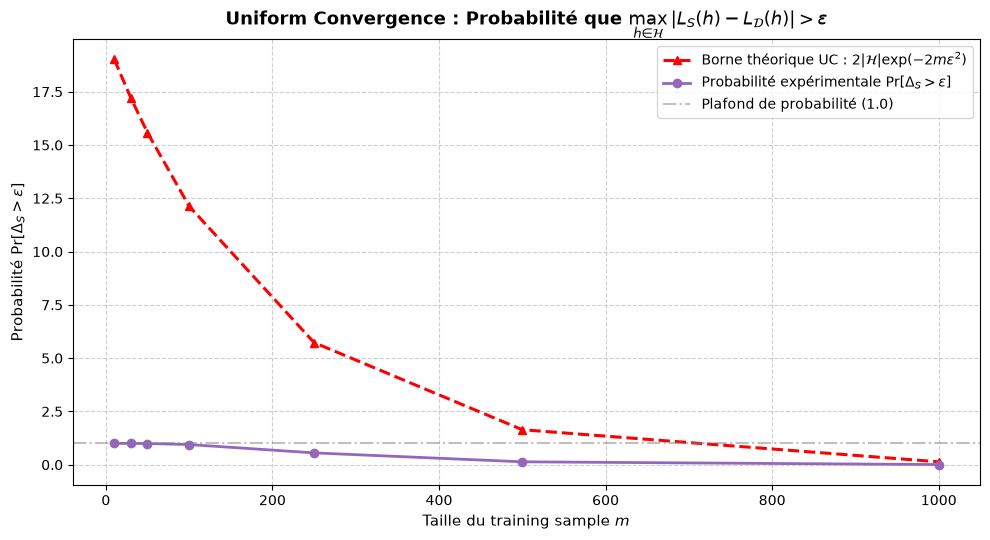

In [4]:
# Définition d'une classe d'hypothèses H de taille K finie
K_TAILLE_H = 10  # Nombre d'hypothèses dans H
# On génère des vrais risques p_j fixés pour chaque hypothèse de H (ex: répartis entre 0.05 et 0.70)
p_hypotheses_H = np.linspace(0.05, 0.70, K_TAILLE_H)

# Paramètres
eps_q3 = 0.05
proba_uc_exp = []
borne_uc_theo = []

print(
    f"Simulation de l'Uniform Convergence (|H| = {K_TAILLE_H}, epsilon ="
    f" {eps_q3}, {N_REPETITIONS} répétitions) :\n"
)

for m in m_tab:
  # Pour chaque répétition de Monte-Carlo, on simule les erreurs empiriques de TOUTES les hypothèses de H simultanément
  # shape de erreurs_emp_matrix : (N_REPETITIONS, K_TAILLE_H)
  erreurs_emp_matrix = np.zeros((N_REPETITIONS, K_TAILLE_H))

  for idx_h, pj in enumerate(p_hypotheses_H):
    erreurs_emp_matrix[:, idx_h] = simuler_risque_empirique(m, pj, N_REPETITIONS)

  # Calcul de la déviation maximale delta_S = max_h |L_S(h) - L_D(h)| pour chaque répétition
  # On soustrait le vecteur p_hypotheses_H à chaque ligne, on prend la valeur absolue, puis le max par ligne
  ecarts_matrix = np.abs(erreurs_emp_matrix - p_hypotheses_H)
  delta_s_tab = np.max(ecarts_matrix, axis=1)

  # Estimation expérimentale de Pr(delta_S > epsilon)
  proba_exp_uc = np.mean(delta_s_tab > eps_q3)
  proba_uc_exp.append(proba_exp_uc)

  # Borne théorique de convergence uniforme : 2 * |H| * exp(-2 * m * epsilon^2)
  borne_theo_uc = 2.0 * K_TAILLE_H * np.exp(-2.0 * m * (eps_q3**2))
  borne_uc_theo.append(borne_theo_uc)

  print(
      f"m = {m:4d} | Pr_exp(max |L_S - L_D| > {eps_q3}) = {proba_exp_uc:.4f} |"
      f" Borne UC Théo = {borne_theo_uc:.4f}"
  )

# Visualisation : Convergence uniforme expérimentale vs Borne théorique
plt.figure(figsize=(10, 5.5))

plt.plot(
    m_tab,
    borne_uc_theo,
    marker="^",
    linestyle="--",
    color="red",
    linewidth=2.2,
    label=r"Borne théorique UC : $2|\mathcal{{H}}|\exp(-2m\epsilon^2)$",
)
plt.plot(
    m_tab,
    proba_uc_exp,
    marker="o",
    linestyle="-",
    color="tab:purple",
    linewidth=2,
    label=r"Probabilité expérimentale $\Pr[\Delta_S > \epsilon]$",
)

plt.axhline(
    y=1.0, color="gray", linestyle="-.", alpha=0.5, label="Plafond de probabilité (1.0)"
)

plt.title(
    r"Uniform Convergence : Probabilité que $\max_{h \in \mathcal{H}}"
    r"|L_S(h) - L_\mathcal{D}(h)| > \epsilon$",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(r"Taille du training sample $m$", fontsize=11)
plt.ylabel(rf"Probabilité $\Pr[\Delta_S > \epsilon]$", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Interprétation de la Question 3 : From One Hypothesis to Uniform Convergence

   * Contrairement à la Question 2 où l'on vérifiait Hoeffding pour *une seule* hypothèse fixée, l'algorithme ERM choisit son hypothèse $h_S$ parmi *toutes* les hypothèses possibles de $\mathcal{H}$ sur le même et unique échantillon $S$. 
   * Si un échantillon $S$ est malchanceux et donne une erreur empirique très élevée d'une seule des hypothèses au-delà de $\epsilon$, l'ERM risque de choisir cette mauvaise hypothèse. Pour garantir que l'ERM fonctionne, il faut donc que *toutes* les hypothèses de $\mathcal{H}$ simultanément respectent $|L_S(h) - L_\mathcal{D}(h)| \le \epsilon$, ce qui correspond exactement au critère de la déviation maximale $\Delta_S = \max_{h \in \mathcal{H}} |L_S(h) - L_\mathcal{D}(h)| \le \epsilon$.
   * Pour passer d'une hypothèse unique à toute la classe $\mathcal{H}$, la théorie utilise l'Union Bound). La probabilité qu'au moins une hypothèse échoue est inférieure ou égale à la *somme* des probabilités d'échec de chaque hypothèse. 
   * C'est de là que vient le facteur multiplicatif $|\mathcal{H}|$ dans la borne théorique $2 |\mathcal{H}| e^{-2 m \epsilon^2}$.

**Analyse des résultats :**
   * On observe que pour de petites tailles d'échantillons ($m = 10$ ou $m = 30$), la probabilité $\Pr[\Delta_S > \epsilon]$ est très proche de $1.0$ : sur de petits échantillons, il est quasi-certain qu'au moins une des $10$ hypothèses aura son erreur empirique qui s'écarte de plus de $5\%$ de son erreur vraie.
   * Lorsque $m$ est plus élevé ($m = 250, 500, 1000$), la probabilité de déviation maximale chute rapidement vers $0.0000$. 
   * Tout comme à la question précédente, la borne théorique reste très conservative (elle dépasse $1$ pour les petits $m$ à cause du terme $2|\mathcal{H}|$ devant l'exponentielle), mais elle confirme que l'uniform convergence est bien assurée dès que $m$ est suffisamment grand.

## 4. Effect of the Size of the Hypothesis Class

D'après la borne théorique de convergence uniforme vue en cours :
$$\Pr\left[\max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{} > \epsilon\right] \le 2 \vert{}\mathcal{H}\vert{} e^{-2 m \epsilon^2}$$

Le terme de la taille de la classe d'hypothèses $\vert{}\mathcal{H}\vert{}$ apparaît en facteur multiplicatif.

### Choix des paramètres :
* Différentes tailles de classes $\vert{}\mathcal{H}\vert{}$ : On teste plusieurs valeurs : `tailles_H = [5, 10, 50, 100, 500]`.
* Précision voulue : On fixe $\epsilon = 0.05$.
* Répétitions : `N_REPETITIONS = 2000`.

Simulation de l'effet de la taille de H (epsilon = 0.05, 2000 répétitions) :

Terminé pour |H| =   5
Terminé pour |H| =  10
Terminé pour |H| =  50
Terminé pour |H| = 100
Terminé pour |H| = 500


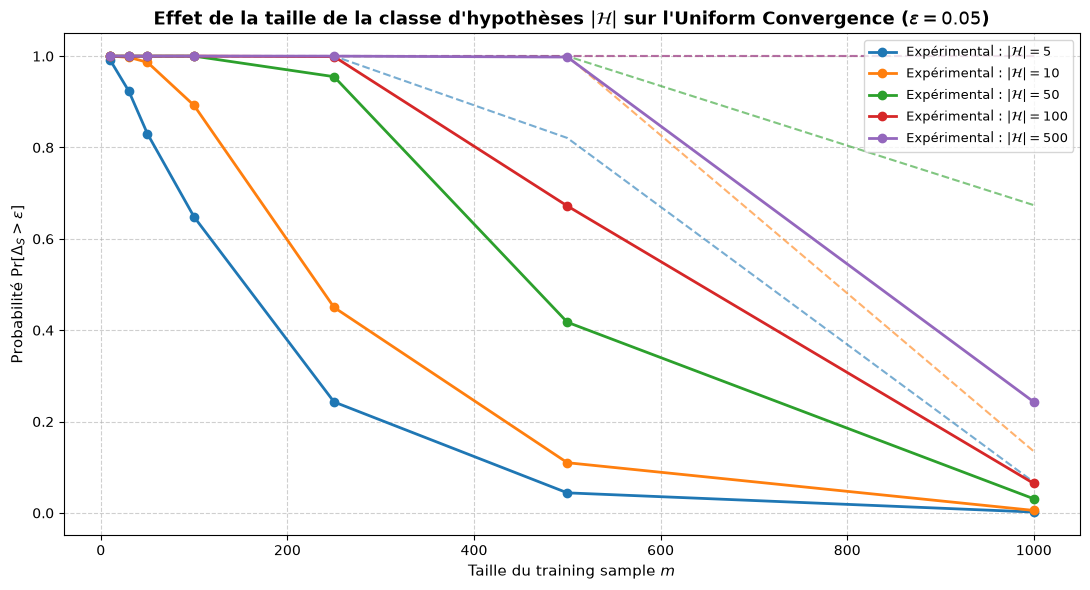

In [5]:
# Paramètres pour la Question 4
tailles_H = [5, 10, 50, 100, 500]
eps_q4 = 0.05
n_rep_q4 = 2000

# Dictionnaire pour stocker les résultats : clés = taille |H|, valeurs = liste des probabilités expérimentales pour chaque m
resultats_q4 = {}

print(
    f"Simulation de l'effet de la taille de H (epsilon = {eps_q4},"
    f" {n_rep_q4} répétitions) :\n"
)

for K in tailles_H:
  # On génère des vrais risques aléatoires mais fixes pour les K hypothèses
  p_class_H = np.linspace(0.02, 0.98, K)
  prob_exp_par_m = []

  for m in m_tab:
    erreurs_matrix = np.zeros((n_rep_q4, K))
    for idx_h, pj in enumerate(p_class_H):
      erreurs_matrix[:, idx_h] = simuler_risque_empirique(m, pj, n_rep_q4)

    # Calcul de la déviation maximale delta_S pour chaque répétition
    delta_s = np.max(np.abs(erreurs_matrix - p_class_H), axis=1)
    # Estimation de Pr(delta_S > epsilon)
    prob_exp = np.mean(delta_s > eps_q4)
    prob_exp_par_m.append(prob_exp)

  resultats_q4[K] = prob_exp_par_m
  print(f"Terminé pour |H| = {K:3d}")

# Visualisation : Probabilité Pr[Delta_S > epsilon] en fonction de m pour différentes tailles de |H|
plt.figure(figsize=(11, 6))

couleurs = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

for idx, K in enumerate(tailles_H):
  # Courbe expérimentale
  plt.plot(
      m_tab,
      resultats_q4[K],
      marker="o",
      linestyle="-",
      color=couleurs[idx],
      linewidth=2,
      label=rf"Expérimental : $|\mathcal{{H}}| = {K}$",
  )

  # Courbe théorique de la borne UC associée pour comparaison
  borne_associee = [
      min(1.0, 2.0 * K * np.exp(-2.0 * m * (eps_q4**2))) for m in m_tab
  ]
  plt.plot(
      m_tab,
      borne_associee,
      linestyle="--",
      color=couleurs[idx],
      alpha=0.6,
      linewidth=1.5,
  )

plt.title(
    r"Effet de la taille de la classe d'hypothèses $|\mathcal{H}|$ sur l'"
    rf"Uniform Convergence ($\epsilon = {eps_q4}$)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(r"Taille du training sample $m$", fontsize=11)
plt.ylabel(rf"Probabilité $\Pr[\Delta_S > \epsilon]$", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=9.5, loc="upper right")
plt.tight_layout()
plt.show()

### Interprétation de la Question 4 : Effect of the Size of the Hypothesis Class

**How does increasing $|\mathcal{H}|$ affect uniform convergence ?**
   * Sur le graphique, on observe clairement que pour une taille d'échantillon $m$ fixée (par exemple $m = 100$ ou $m = 250$), la courbe de probabilité d'échec $\Pr[\Delta_S > \epsilon]$ se décale vers la droite lorsque $|\mathcal{H}|$ augmente (passant de $5$ à $500$ hypothèses).
   * Plus la classe d'hypothèses est grande, plus la probabilité qu'au moins une de ses hypothèses subisse un écart important entre risque empirique et risque vrai est élevée.

**Does a larger hypothesis class generally require more data ?**
   * Oui. En effet, pour maintenir la même garantie de fiabilité (par exemple pour que la probabilité d'échec descende sous les 5%, il faut un nombre d'exemples d'entraînement $m$ beaucoup plus grand si $|\mathcal{H}|$ est grand. 
   * C'est la traduction directe du terme $|\mathcal{H}|$ dans la borne de convergence uniforme $2|\mathcal{H}|e^{-2m\epsilon^2}$ : si $|\mathcal{H}|$ augmente, il faut compenser en augmentant $m$ pour que l'exponentielle négative annule cette augmentation.

**How does this relate to the $\log|\mathcal{H}|$ dependence appearing in finite-class sample-complexity
bounds ?**
   * On a la borne vue pour l'Uniform Convergence :
   $$m \ge \frac{\log(2|\mathcal{H}|/\delta)}{2\epsilon^2} = \frac{\log(2/\delta) + \log|\mathcal{H}|}{2\epsilon^2}$$
   * On constate que le nombre d'exemples requis $m$ ne dépend pas linéairement de la taille de la classe $|\mathcal{H}|$, mais plutôt de manière logarithmique ($\log|\mathcal{H}|$). C'est une excellente nouvelle en machine learning : cela signifie qu'on peut multiplier par 10 ou 100 le nombre d'hypothèses dans notre modèle, le nombre de données d'entraînement nécessaires n'aura besoin d'augmenter que de façon très modérée (additivement via son log).

## 5. Experimental Sample Complexity

### Paramètres fixés :
* Précision voulue : $\epsilon = 0.05$
* Confiance : $\delta = 0.05$ (on veut que $\Pr[\Delta_S > \epsilon] \le \delta$, c'est-à-dire une garantie de succès de $95\%$)
* Taille de la classe d'hypothèses : On fixe $|\mathcal{H}| = K = 10$

In [6]:
# Paramètres pour la Question 5
EPSILON_Q5 = 0.05
DELTA_Q5 = 0.05
K_Q5 = 10  # |H|

# 1. Calcul de la taille d'échantillon suffisante théorique
m_theorique = np.ceil(
    np.log(2.0 * K_Q5 / DELTA_Q5) / (2.0 * (EPSILON_Q5**2))
)
print(f"--- Résultats de la Question 5 ---")
print(
    f"Taille d'échantillon minimale suffisante théorique (Formule) : m >="
    f" {int(m_theorique)}"
)

# 2. Détermination expérimentale de la plus petite taille m testée dans m_tab pour laquelle Pr[Delta_S > epsilon] <= delta
m_experimental_trouve = None

print(f"\nRecherche de la taille d'échantillon expérimentale (N = 2000) :")
# On utilise un tableau de m plus fin pour être plus précis dans la recherche expérimentale
m_fin_tab = [10, 30, 50, 100, 250, 500, 750, 1000, 1500, 2000]

p_class_H_q5 = np.linspace(0.05, 0.45, K_Q5)
n_rep_q5 = 2000

for m in m_fin_tab:
  erreurs_matrix = np.zeros((n_rep_q5, K_Q5))
  for idx_h, pj in enumerate(p_class_H_q5):
    erreurs_matrix[:, idx_h] = simuler_risque_empirique(m, pj, n_rep_q5)

  delta_s = np.max(np.abs(erreurs_matrix - p_class_H_q5), axis=1)
  proba_echec = np.mean(delta_s > EPSILON_Q5)

  respecte_garantie = proba_echec <= DELTA_Q5
  print(
      f"m = {m:4d} | Pr(max |L_S - L_D| > {EPSILON_Q5}) = {proba_echec:.4f} |"
      f" Garantie respectée (<= {DELTA_Q5}) : {respecte_garantie}"
  )

  if respecte_garantie and m_experimental_trouve is None:
    m_experimental_trouve = m

print(
    f"\n-> Plus petite taille m testée validant la garantie PAC : m ="
    f" {m_experimental_trouve}"
)

--- Résultats de la Question 5 ---
Taille d'échantillon minimale suffisante théorique (Formule) : m >= 1199

Recherche de la taille d'échantillon expérimentale (N = 2000) :
m =   10 | Pr(max |L_S - L_D| > 0.05) = 1.0000 | Garantie respectée (<= 0.05) : False
m =   30 | Pr(max |L_S - L_D| > 0.05) = 0.9970 | Garantie respectée (<= 0.05) : False
m =   50 | Pr(max |L_S - L_D| > 0.05) = 0.9905 | Garantie respectée (<= 0.05) : False
m =  100 | Pr(max |L_S - L_D| > 0.05) = 0.9205 | Garantie respectée (<= 0.05) : False
m =  250 | Pr(max |L_S - L_D| > 0.05) = 0.4595 | Garantie respectée (<= 0.05) : False
m =  500 | Pr(max |L_S - L_D| > 0.05) = 0.0995 | Garantie respectée (<= 0.05) : False
m =  750 | Pr(max |L_S - L_D| > 0.05) = 0.0240 | Garantie respectée (<= 0.05) : True
m = 1000 | Pr(max |L_S - L_D| > 0.05) = 0.0060 | Garantie respectée (<= 0.05) : True
m = 1500 | Pr(max |L_S - L_D| > 0.05) = 0.0005 | Garantie respectée (<= 0.05) : True
m = 2000 | Pr(max |L_S - L_D| > 0.05) = 0.0000 | Garanti

### Interprétation de la Question 5 : Experimental Sample Complexity

   * En appliquant la formule théorique du cours pour $|\mathcal{H}| = 10$, $\epsilon = 0.05$ et $\delta = 0.05$ :
   $$m \ge \frac{\log(2 \times 10 / 0.05)}{2 \times (0.05)^2} = \frac{\log(400)}{0.005} \approx \frac{5.99}{0.005} \approx 1198 \text{ exemples}$$
Du côté de l'expérience, on constate que la probabilité d'échec descend sous les $\delta = 0.05$ dès que $m=750$ ce qui est nettement inférieur à la borne théorique de $1198$.


   * Tout comme nous l'avions observé pour la borne de Hoeffding à la Question 2, la borne de complexité d'échantillon issue de la convergence uniforme est conservative. Les raisons sont notamment :
1. L'inégalité de l'Union au pire des cas : La théorie additionne les risques d'échec de *toutes* les hypothèses en supposant qu'elles peuvent toutes mal se comporter en même temps dans le pire des cas, alors qu'en réalité, des erreurs peuvent être bien plus faibles.
2. Indépendance vis-à-vis de la distribution : La formule est universelle et s'applique à n'importe quelle distribution de probabilité et à n'importe quel ensemble de risques $p_j$, sans exploiter la structure spécifique de la classe testée.

* En conclusion, la borne théorique garantit mathématiquement qu'au-delà de $m \ge 1198$ exemples, on a bien la garantie, mais la réalité expérimentale montre qu'en pratique, un nombre de données plus faible peut suffir amplement pour réussir l'apprentissage.

# Part II – Simulating No-Free-Lunch

## 6. Seen and Unseen Inputs

### Choix et justification des paramètres expérimentaux :
* Tailles du domaine ($N$) : On choisit `N_tab = [50, 100, 500]` afin d'observer comment la taille de l'espace d'entrée $\mathcal{X}$ influence la proportion de points jamais vus pour un même nombre d'exemples $m$.
* Tailles d'échantillon ($m$) : On choisit `m_tab_nfl = [10, 25, 50, 100, 200, 300, 500]`. Ces valeurs permettent d'étudier tous les régimes : le cas où $m < N/2$ (hypothèse du théorème No-Free-Lunch en CM4), le cas où $m = N$, et le cas où $m > N$.
* Nombre de répétitions de Monte-Carlo : On fixe `N_REP_NFL = 2000` répétitions par couple $(N, m)$ pour obtenir une estimation très précise de la fraction moyenne d'entrées non vues.

In [7]:
# Fixer la graine aléatoire pour toujours obtenir les mêmes résultats
np.random.seed(0)

# Paramètres expérimentaux
# Différentes tailles du domaine fini X = {1, ..., N}
N_tab = [50, 100, 500]
# Différentes tailles du training sample m
m_tab_nfl = [
    10,
    25,
    50,
    100,
    200,
    300,
    500,
]
# Nombre de répétitions de Monte-Carlo
N_REP_NFL = 2000


def generer_cible_aleatoire(N):
  """(Question a)) Génère une fonction cible f : X -> {0, 1} complètement aléatoire.

  Pour chaque x dans {1, ..., N}, f(x) est tiré selon Bernoulli(1/2). 
  Retourne un tableau 1D de taille N contenant les étiquettes dans {0, 1}. 
  (indice i du tableau correspond à l'élément x = i + 1).
  """
  f_tab = np.random.randint(0, 2, size=N)
  return f_tab


def generer_sample_nfl(N, m, f_tab):
  """(Question b)) Génère un training sample S de taille m tiré uniformément dans X = {1, ..., N}.
  Retourne : 
  - x_sample : les indices (entre 0 et N-1) des exemples tirés dans S
  - y_sample : leurs étiquettes correspondantes f(x)
  """
  # Tirage uniforme avec remise de m éléments parmi les N éléments du domaine (indicés de 0 à N-1)
  x_sample = np.random.randint(0, N, size=m)
  y_sample = f_tab[x_sample]
  return x_sample, y_sample


def simuler_fraction_unseen(N, m, n_rep=N_REP_NFL):
  """(Question c)) Répète n_rep fois la génération d'une cible aléatoire et d'un sample S de taille m,
    et calcule la fraction moyenne d'éléments de X qui n'apparaissent jamais dans S.
  """
  fractions_unseen = np.zeros(n_rep)

  for rep in range(n_rep):
    # (a) Génération de la fonction cible aléatoire f
    f_tab = generer_cible_aleatoire(N)

    # (b) Génération du training sample S de taille m
    x_sample, _ = generer_sample_nfl(N, m, f_tab)

    # (c) Calcul du nombre d'éléments distincts vus (seen) dans S grâce à np.unique
    nb_seen = len(np.unique(x_sample))
    nb_unseen = N - nb_seen

    # Fraction d'entrées de X jamais observées dans S
    fractions_unseen[rep] = nb_unseen / N

  return np.mean(fractions_unseen)


# Exécution des simulations et comparaison avec la formule théorique (1 - 1/N)^m
resultats_q6_exp = {}
resultats_q6_theo = {}

print(
    "Comparaison Fraction Unseen Expérimentale vs Théorique (1 - 1/N)^m sur"
    f" {N_REP_NFL} répétitions :\n"
)

for N in N_tab:
  resultats_q6_exp[N] = []
  resultats_q6_theo[N] = []
  print(f"--- Domaine de taille N = {N} ---")

  for m in m_tab_nfl:
    frac_exp = simuler_fraction_unseen(N, m, N_REP_NFL)
    frac_theo = (1.0 - 1.0 / N) ** m

    resultats_q6_exp[N].append(frac_exp)
    resultats_q6_theo[N].append(frac_theo)

    print(
        f"m = {m:3d} | Fraction Unseen Exp = {frac_exp:.4f} | Théorique (1 -"
        f" 1/N)^m = {frac_theo:.4f} | Écart = {abs(frac_exp - frac_theo):.4f}"
    )
  print()

Comparaison Fraction Unseen Expérimentale vs Théorique (1 - 1/N)^m sur 2000 répétitions :

--- Domaine de taille N = 50 ---
m =  10 | Fraction Unseen Exp = 0.8173 | Théorique (1 - 1/N)^m = 0.8171 | Écart = 0.0002
m =  25 | Fraction Unseen Exp = 0.6026 | Théorique (1 - 1/N)^m = 0.6035 | Écart = 0.0009
m =  50 | Fraction Unseen Exp = 0.3628 | Théorique (1 - 1/N)^m = 0.3642 | Écart = 0.0014
m = 100 | Fraction Unseen Exp = 0.1324 | Théorique (1 - 1/N)^m = 0.1326 | Écart = 0.0003
m = 200 | Fraction Unseen Exp = 0.0181 | Théorique (1 - 1/N)^m = 0.0176 | Écart = 0.0005
m = 300 | Fraction Unseen Exp = 0.0022 | Théorique (1 - 1/N)^m = 0.0023 | Écart = 0.0001
m = 500 | Fraction Unseen Exp = 0.0001 | Théorique (1 - 1/N)^m = 0.0000 | Écart = 0.0000

--- Domaine de taille N = 100 ---
m =  10 | Fraction Unseen Exp = 0.9045 | Théorique (1 - 1/N)^m = 0.9044 | Écart = 0.0001
m =  25 | Fraction Unseen Exp = 0.7777 | Théorique (1 - 1/N)^m = 0.7778 | Écart = 0.0001
m =  50 | Fraction Unseen Exp = 0.6052 |

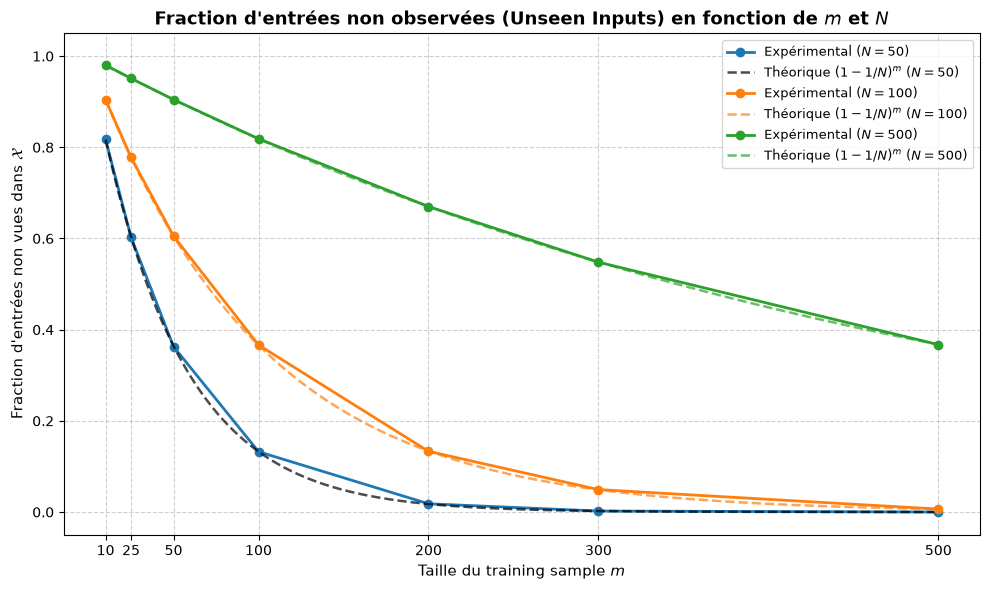

In [8]:
# Visualisation : Évolution de la fraction d'entrées non vues (unseen) en fonction de m
plt.figure(figsize=(10, 6))

couleurs = ['tab:blue', 'tab:orange', 'tab:green']

for idx, N in enumerate(N_tab):
  c = couleurs[idx]
  # Courbe expérimentale (points reliés par trait plein)
  plt.plot(
      m_tab_nfl,
      resultats_q6_exp[N],
      marker='o',
      linestyle='-',
      color=c,
      linewidth=2,
      markersize=6,
      label=rf'Expérimental ($N = {N}$)',
  )
  # Courbe théorique lisse pour bien voir la superposition
  m_grille = np.linspace(min(m_tab_nfl), max(m_tab_nfl), 300)
  courbe_theo = (1.0 - 1.0 / N) ** m_grille
  plt.plot(
      m_grille,
      courbe_theo,
      linestyle='--',
      color='black' if idx == 0 else c,
      alpha=0.7,
      linewidth=1.8,
      label=rf'Théorique $(1 - 1/N)^m$ ($N = {N}$)',
  )

plt.title(
    "Fraction d'entrées non observées (Unseen Inputs) en fonction de $m$ et"
    ' $N$',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel(r'Taille du training sample $m$', fontsize=11)
plt.ylabel(r"Fraction d'entrées non vues dans $\mathcal{X}$", fontsize=11)
plt.xticks(m_tab_nfl)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9.5, loc='upper right')
plt.tight_layout()
plt.show()

### Interprétation et analye de la Question 6 : Seen and Unseen Inputs

**1. Explication $\Pr[x \text{ is unseen}] = \left(1 - \frac{1}{N}\right)^m$ sur la probabilité qu'un point fixé $x \in \mathcal{X}$ ne soit jamais tiré) :**
* Lors d'un seul tirage uniforme dans $\mathcal{X} = \{1, \dots, N\}$, la probabilité de tirer un point précis $x$ est $\frac{1}{N}$. La probabilité de ne pas tirer ce point $x$ lors de ce tirage est donc $1 - \frac{1}{N}$.
     Comme le training sample $S = (x_1, \dots, x_m)$ est constitué de $m$ tirages indépendants et identiquement distribués (i.i.d.) avec remise, la probabilité que $x$ n'apparaisse dans aucun des $m$ tirages est le produit des probabilités :
     $$\Pr[x \text{ is unseen}] = \Pr\left(\bigcap_{i=1}^m \{x_i \neq x\}\right) = \left(1 - \frac{1}{N}\right)^m$$

**2. Comparaison entre nos simulations expérimentales et la théorie :**
   * Sur le graphique ainsi que dans les résultats affichés, les moyennes expérimentales obtenues par simulation de Monte-Carlo (`N_REP_NFL = 2000`) sont très proches de la courbe théorique $\left(1 - \frac{1}{N}\right)^m$ (l'écart est inférieur à $0.009$).
   * Lien avec le théorème du No-Free-Lunch : Dans l'énoncé du théorème du No-Free-Lunch, on suppose $m < \frac{N}{2}$ (soit un échantillon deux fois plus petit que le domaine). Nos résultats montrent que pour $m = \frac{N}{2}$ (ex: $m=50$ pour $N=100$), la proportion d'entrées jamais vues avec remise est d'environ $\left(1 - \frac{1}{N}\right)^{N/2} \approx e^{-1/2} \approx 60.65\%$ (ce qui est bien supérieur aux $50\%$ minimum garantie). Plus $N$ est grand par rapport à $m$ (ex: $N=500$, courbe verte), plus on a une plus grande partie de l'espace d'entrée qui reste unseen pendant l'entraînement.

## 7. Error on Unseen Inputs

In [9]:
np.random.seed(0)


def apprendre_memorisation(N, x_sample, y_sample, valeur_defaut=0):
  """Implémente le Memorizing Learner A(S) sur le domaine X = {1, ..., N}.

  Entrées :
  - N (int) : Taille du domaine X.
  - x_sample (np.ndarray) : Indices des entrées x observées dans S.
  - y_sample (np.ndarray) : Étiquettes f(x) observées dans S.
  - valeur_defaut (int) : Prédiction pour les entrées jamais vues (0 par
  défaut).
  Retourne :
  - h_tab (np.ndarray) : Tableau de taille N contenant les prédictions A(S)(x)
  pour tout x dans X.
  """
  # 1. Par défaut, toutes les entrées du domaine sont initialisées à valeur_defaut (0 pour les unseen inputs)
  h_tab = np.full(N, valeur_defaut, dtype=int)

  # 2. Pour toutes les entrées x apparues dans S (seen inputs), on mémorise leur vraie étiquette observée y
  h_tab[x_sample] = y_sample

  return h_tab


def calculer_true_risk_domaine(h_tab, f_tab):
  """Calcule le true risk exact L_D(A(S)) sur l'ensemble du domaine fini X muni de la loi uniforme :

  L_D(A(S)) = (1 / N) * sum_{x in X} 1{A(S)(x) != f(x)}
  """
  erreurs = np.where(h_tab != f_tab, 1, 0)
  return np.mean(erreurs)


def simuler_erreur_memorisation(N, m, n_rep=N_REP_NFL):
  """Répète n_rep fois l'expérience (nouvelle cible aléatoire f + nouveau sample S de taille m)
  et retourne la moyenne empirique du true risk L_D(A(S)).
  """
  risques_vrais = np.zeros(n_rep)

  for rep in range(n_rep):
    # 1. Nouvelle fonction cible complètement aléatoire f ~ Bernoulli(1/2)
    f_tab = generer_cible_aleatoire(N)

    # 2. Nouveau training sample S de taille m
    x_sample, y_sample = generer_sample_nfl(N, m, f_tab)

    # 3. Apprentissage par mémorisation A(S) (prédit 0 sur les unseen inputs)
    h_tab = apprendre_memorisation(N, x_sample, y_sample, valeur_defaut=0)

    # 4. Évaluation du true risk sur tout le domaine X
    risques_vrais[rep] = calculer_true_risk_domaine(h_tab, f_tab)

  return np.mean(risques_vrais)


# Exécution des simulations pour nos différentes valeurs de N et m
resultats_q7_exp = {}
resultats_q7_theo = {}

print(
    "Comparaison True Risk Moyen Expérimental vs Théorique 0.5 * (1 - 1/N)^m"
    f" ({N_REP_NFL} répétitions) :\n"
)

for N in N_tab:
  resultats_q7_exp[N] = []
  resultats_q7_theo[N] = []
  print(f"--- Domaine de taille N = {N} ---")

  for m in m_tab_nfl:
    risque_exp = simuler_erreur_memorisation(N, m, N_REP_NFL)
    risque_theo = 0.5 * ((1.0 - 1.0 / N) ** m)

    resultats_q7_exp[N].append(risque_exp)
    resultats_q7_theo[N].append(risque_theo)

    print(
        f"m = {m:3d} | E[L_D(A(S))] Exp = {risque_exp:.4f} | Théorique ="
        f" {risque_theo:.4f} | Écart = {abs(risque_exp - risque_theo):.4f}"
    )
  print()

Comparaison True Risk Moyen Expérimental vs Théorique 0.5 * (1 - 1/N)^m (2000 répétitions) :

--- Domaine de taille N = 50 ---
m =  10 | E[L_D(A(S))] Exp = 0.4083 | Théorique = 0.4085 | Écart = 0.0002
m =  25 | E[L_D(A(S))] Exp = 0.3018 | Théorique = 0.3017 | Écart = 0.0001
m =  50 | E[L_D(A(S))] Exp = 0.1804 | Théorique = 0.1821 | Écart = 0.0016
m = 100 | E[L_D(A(S))] Exp = 0.0661 | Théorique = 0.0663 | Écart = 0.0002
m = 200 | E[L_D(A(S))] Exp = 0.0092 | Théorique = 0.0088 | Écart = 0.0004
m = 300 | E[L_D(A(S))] Exp = 0.0011 | Théorique = 0.0012 | Écart = 0.0000
m = 500 | E[L_D(A(S))] Exp = 0.0000 | Théorique = 0.0000 | Écart = 0.0000

--- Domaine de taille N = 100 ---
m =  10 | E[L_D(A(S))] Exp = 0.4524 | Théorique = 0.4522 | Écart = 0.0002
m =  25 | E[L_D(A(S))] Exp = 0.3897 | Théorique = 0.3889 | Écart = 0.0008
m =  50 | E[L_D(A(S))] Exp = 0.3015 | Théorique = 0.3025 | Écart = 0.0010
m = 100 | E[L_D(A(S))] Exp = 0.1821 | Théorique = 0.1830 | Écart = 0.0009
m = 200 | E[L_D(A(S))] E

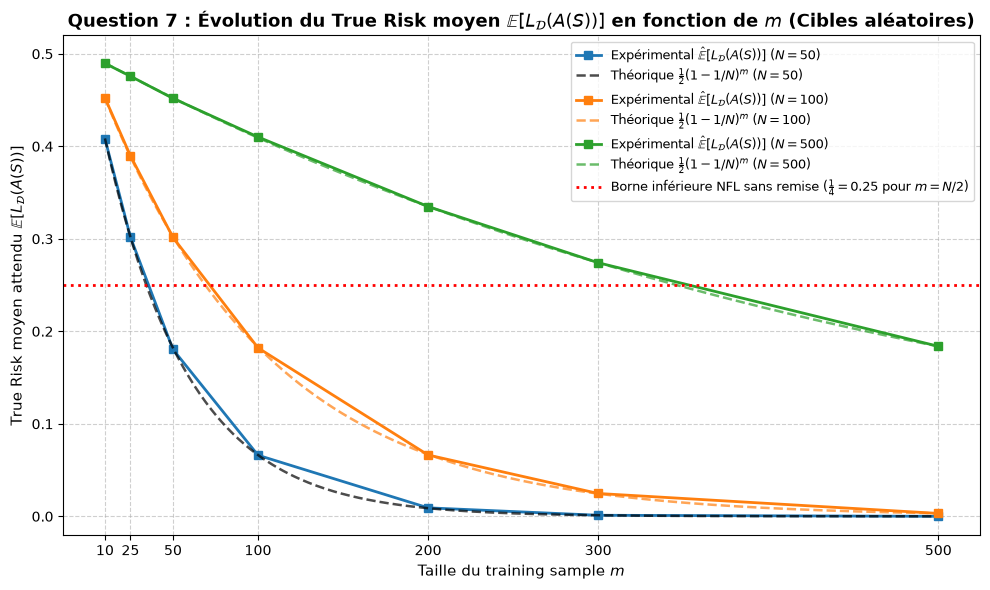

In [10]:
# Visualisation : Comparaison du True Risk attendu expérimental et théorique en fonction de m
plt.figure(figsize=(10, 6))

couleurs = ['tab:blue', 'tab:orange', 'tab:green']

for idx, N in enumerate(N_tab):
  c = couleurs[idx]
  # Courbe expérimentale
  plt.plot(
      m_tab_nfl,
      resultats_q7_exp[N],
      marker='s',
      linestyle='-',
      color=c,
      linewidth=2,
      markersize=6,
      label=(
          rf'Expérimental $\hat{{\mathbb{{E}}}}[L_\mathcal{{D}}(A(S))]$ ($N ='
          rf' {N}$)'
      ),
  )

  # Courbe théorique lisse
  m_grille = np.linspace(min(m_tab_nfl), max(m_tab_nfl), 300)
  courbe_theo = 0.5 * ((1.0 - 1.0 / N) ** m_grille)
  plt.plot(
      m_grille,
      courbe_theo,
      linestyle='--',
      color='black' if idx == 0 else c,
      alpha=0.7,
      linewidth=1.8,
      label=rf'Théorique $\frac{{1}}{{2}}(1 - 1/N)^m$ ($N = {N}$)',
  )

# Ligne horizontale à 0.25 (seuil critique du théorème No-Free-Lunch quand m <= N/2)
plt.axhline(
    y=0.25,
    color='red',
    linestyle=':',
    linewidth=2,
    label=(
        r'Borne inférieure NFL sans remise ($\frac{1}{4} = 0.25$ pour $m ='
        r' N/2$)'
    ),
)

plt.title(
    r'Question 7 : Évolution du True Risk moyen'
    r' $\mathbb{E}[L_\mathcal{D}(A(S))]$ en fonction de $m$ (Cibles'
    r' aléatoires)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel(r'Taille du training sample $m$', fontsize=11)
plt.ylabel(
    r'True Risk moyen attendu $\mathbb{E}[L_\mathcal{D}(A(S))]$', fontsize=11
)
plt.xticks(m_tab_nfl)
plt.ylim(-0.02, 0.52)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

### Interprétation de la Question 7 : Error on Unseen Inputs

**1. Comparaison entre les résultats de l'expérience et la formule théorique :**
   * Pour toutes les tailles de domaine $N \in \{50, 100, 500\}$ et toutes les tailles d'échantillons $m$, la moyenne expérimentale du true risk $\hat{\mathbb{E}}[L_\mathcal{D}(A(S))]$ semble suivre exactement la formule théorique $\frac{1}{2}\left(1 - \frac{1}{N}\right)^m$.
   * On observe que le true risk moyen vaut la moitié de la fraction de unseen points calculée à la Question 6. Cela semble cohérent. En effet, sur les points vus ($x \in S$), l'erreur est de $0\%$, tandis que sur les points non vus ($x \notin S$), prédire $0$ face à une étiquette tirée à pile ou face donne exactement $50\%$ d'erreur en moyenne.

**2. L'erreur diminue par mémorisation et non pas par généralisation :**
   * On remarque que lorsque $m$ augmente par rapport à $N$ (par exemple pour un petit domaine $N=50$ avec $m=200$ ou $m=500$), l'erreur vraie finit par tendre vers $0$.
   * Cette baisse de l'erreur ne vient pas du fait que l'algorithme a "compris une règle générale" lui permettant de deviner les points non vus. Sur ces points unseen, son taux d'erreur reste constamment bloqué à $50\%$ (comme un tirage au sort). L'erreur globale ne baisse que parce que l'échantillon $m$ devient tellement grand par rapport à la taille finie $N$ du domaine qu'on finit par avoir vu (et mémorisé par cœur) la quasi-totalité des $N$ éléments possibles de $\mathcal{X}$.
   * À l'inverse, dès que le domaine est grand par rapport à l'échantillon (par exemple $N = 500$ avec $m = 50$), l'erreur vraie reste très élevée ($\approx 0.452$, proche des $50\%$ du pur hasard), alors même que l'erreur d'entraînement $L_S(A(S))$ vaut $0$ : c'est un cas extrême d'overfitting par mémorisation ce qui ressemble à l'exemple des points dans le lac ou en dehors du lac dans le premier cours.

## 8. Changing the Prediction on Unseen Inputs

### Analyse théorique de l'espérance du True Risk pour ces stratégies :
Soit $U_S$ la proportion d'entrées du domaine $\mathcal{X}$ qui n'ont jamais été observées dans l'échantillon d'entraînement $S$ (avec $\mathbb{E}[U_S] = \left(1 - \frac{1}{N}\right)^m$). 

* **Pour les entrées vues ($x \in S$) :** L'algorithme mémorise la vraie étiquette $f(x)$, donc l'erreur commise est toujours de $0$.
* **Pour les entrées non vues ($x \notin S$) :**
  * Si la stratégie consiste à toujours prédire une constante (0 ou 1) : comme la vraie étiquette $f(x)$ d'un point non vu est indépendante et suit une $\text{Bernoulli}(1/2)$, la probabilité de se tromper sur un point non vu est exactement de **$\frac{1}{2}$**. Le true risk moyen global est donc :
    $$\mathbb{E}[L_\mathcal{D}(A_\text{constante}(S))] = \frac{1}{2} \mathbb{E}[U_S] = \frac{1}{2}\left(1 - \frac{1}{N}\right)^m$$
  * Si la stratégie consiste à prédire un label aléatoire $\text{Bernoulli}(1/2)$ : la prédiction est indépendante de la vraie étiquette $f(x)$ (qui est elle-même un tirage $\text{Bernoulli}(1/2)$). La probabilité de se tromper en comparant deux variables de Bernoulli indépendantes de même paramètre $1/2$ est :
    $$\Pr[\text{Prédiction} \neq f(x)] = \frac{1}{2} \times \frac{1}{2} + \frac{1}{2} \times \frac{1}{2} = \frac{1}{2}$$
    Le true risk moyen global reste donc également :
    $$\mathbb{E}[L_\mathcal{D}(A_\text{aleatoire}(S))] = \frac{1}{2} \mathbb{E}[U_S] = \frac{1}{2}\left(1 - \frac{1}{N}\right)^m$$

* Conclusion théorique : Aucune de ces stratégies de contournement ne permet de battre les autres lorsque la fonction cible est totalement aléatoire. Leurs risques vrais moyens sont rigoureusement identiques, illustrant à nouveau le principe du No-Free-Lunch : sans hypothèse sur la structure de $f$, deviner les étiquettes cachées revient statistiquement à jouer à pile ou face.

In [11]:
np.random.seed(0)


def simuler_strategies_alternatives(N, m, n_rep=N_REP_NFL):
  """Simule et compare les true risks moyens de différentes stratégies de prédiction

  pour les unseen inputs dans le cadre du No-Free-Lunch.
  """
  risques_0 = np.zeros(n_rep)
  risques_1 = np.zeros(n_rep)
  risques_rand = np.zeros(n_rep)

  for rep in range(n_rep):
    # 1. Génération de la fonction cible aléatoire f
    f_tab = generer_cible_aleatoire(N)

    # 2. Génération du training sample S
    x_sample, y_sample = generer_sample_nfl(N, m, f_tab)

    # 3. Application des différentes stratégies
    # Stratégie A : prédire 0 sur les unseen
    h_0 = apprendre_memorisation(N, x_sample, y_sample, valeur_defaut=0)
    # Stratégie B : prédire 1 sur les unseen
    h_1 = apprendre_memorisation(N, x_sample, y_sample, valeur_defaut=1)
    # Stratégie C : prédire un choix aléatoire {0, 1} sur les unseen
    h_rand = apprendre_memorisation(N, x_sample, y_sample, valeur_defaut=0)
    # On remplace les positions non vues (qui valent 0 par défaut) par des tirages aléatoires binaires
    unseen_mask = np.ones(N, dtype=bool)
    unseen_mask[x_sample] = False
    h_rand[unseen_mask] = np.random.randint(0, 2, size=np.sum(unseen_mask))

    # 4. Calcul des true risks correspondants
    risques_0[rep] = calculer_true_risk_domaine(h_0, f_tab)
    risques_1[rep] = calculer_true_risk_domaine(h_1, f_tab)
    risques_rand[rep] = calculer_true_risk_domaine(h_rand, f_tab)

  return np.mean(risques_0), np.mean(risques_1), np.mean(risques_rand)


# Test des stratégies pour un domaine N = 100 sur différentes tailles m
print(
    "Comparaison des stratégies alternatives sur les unseen inputs (N = 100,"
    f" {N_REP_NFL} répétitions) :\n"
)
print(f"{'m':>4} | {'Stratégie (Toujours 0)':>22} | {'Stratégie (Toujours 1)':>22} | {'Stratégie (Aléatoire)':>22} | {'Théorique 0.5*(1-1/N)^m':>22}")
print("-" * 105)

for m in m_tab_nfl:
  r0, r1, r_rand = simuler_strategies_alternatives(100, m, N_REP_NFL)
  r_theo = 0.5 * ((1.0 - 1.0 / 100) ** m)
  print(
      f"{m:4d} | {r0:22.4f} | {r1:22.4f} | {r_rand:22.4f} | {r_theo:22.4f}"
  )

Comparaison des stratégies alternatives sur les unseen inputs (N = 100, 2000 répétitions) :

   m | Stratégie (Toujours 0) | Stratégie (Toujours 1) |  Stratégie (Aléatoire) | Théorique 0.5*(1-1/N)^m
---------------------------------------------------------------------------------------------------------
  10 |                 0.4532 |                 0.4508 |                 0.4527 |                 0.4522
  25 |                 0.3879 |                 0.3900 |                 0.3890 |                 0.3889
  50 |                 0.3010 |                 0.3039 |                 0.3015 |                 0.3025
 100 |                 0.1820 |                 0.1838 |                 0.1824 |                 0.1830
 200 |                 0.0670 |                 0.0668 |                 0.0673 |                 0.0670
 300 |                 0.0243 |                 0.0242 |                 0.0243 |                 0.0245
 500 |                 0.0032 |                 0.0034 |         

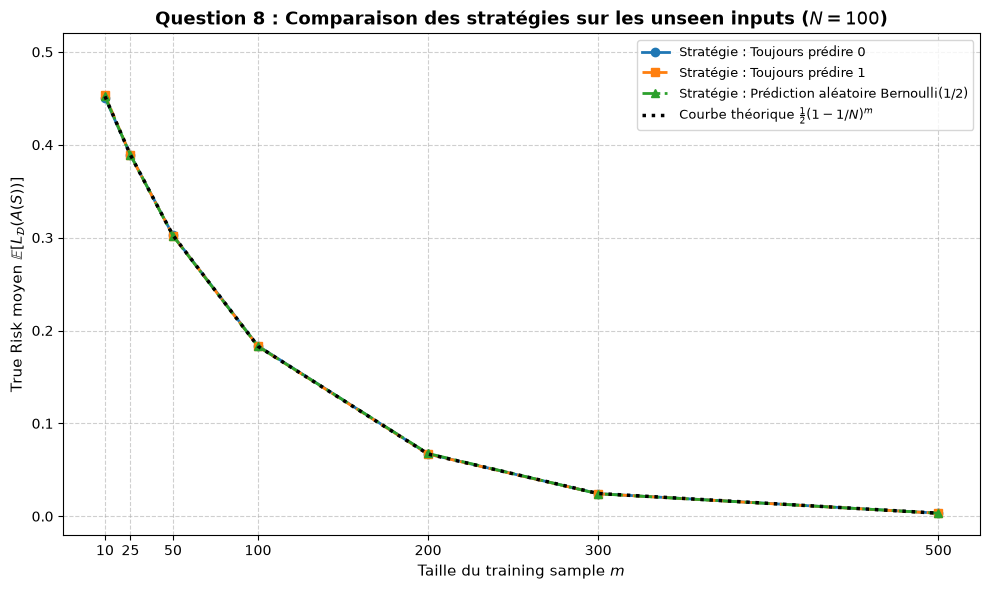

In [12]:
# Visualisation comparative de l'évolution du True Risk pour les différentes stratégies (avec N = 100)
N_visu = 100
exp_0 = []
exp_1 = []
exp_rand = []
theo_nfl = []

for m in m_tab_nfl:
  r0, r1, r_rand = simuler_strategies_alternatives(N_visu, m, N_REP_NFL)
  exp_0.append(r0)
  exp_1.append(r1)
  exp_rand.append(r_rand)
  theo_nfl.append(0.5 * ((1.0 - 1.0 / N_visu) ** m))

plt.figure(figsize=(10, 6))
plt.plot(
    m_tab_nfl,
    exp_0,
    marker='o',
    linestyle='-',
    color='tab:blue',
    linewidth=2,
    label='Stratégie : Toujours prédire 0',
)
plt.plot(
    m_tab_nfl,
    exp_1,
    marker='s',
    linestyle='--',
    color='tab:orange',
    linewidth=2,
    label='Stratégie : Toujours prédire 1',
)
plt.plot(
    m_tab_nfl,
    exp_rand,
    marker='^',
    linestyle='-.',
    color='tab:green',
    linewidth=2,
    label='Stratégie : Prédiction aléatoire Bernoulli(1/2)',
)
plt.plot(
    m_tab_nfl,
    theo_nfl,
    linestyle=':',
    color='black',
    linewidth=2.5,
    label=r'Courbe théorique $\frac{1}{2}(1 - 1/N)^m$',
)

plt.title(
    r'Question 8 : Comparaison des stratégies sur les unseen inputs ($N = 100$)'
    '',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel(r'Taille du training sample $m$', fontsize=11)
plt.ylabel(r'True Risk moyen $\mathbb{E}[L_\mathcal{D}(A(S))]$', fontsize=11)
plt.xticks(m_tab_nfl)
plt.ylim(-0.02, 0.52)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9.5, loc='upper right')
plt.tight_layout()
plt.show()

### Interprétation et conclusion de la Question 8 : Changing the Prediction on Unseen Inputs

**1. Aucune stratégie n'est meilleure que les autres :**
   * Comme le montrent le tableau et le graphique, les courbes des trois stratégies (toujours $0$, toujours $1$, ou tirage aléatoire) se confondent parfaitement avec la courbe théorique. Aucune de ces règles de décision ne parvient à surpasser les autres.

**2. Lien avec le principe du No-Free-Lunch (NFL) :**
   * Cette expérience illustre bien le cœur du théorème du *No-Free-Lunch* : puisque la fonction cible est tirée de manière complètement uniforme et aléatoire parmi toutes les fonctions possibles, aucune information sur les entrées non observées ne peut être déduite des données d'entraînement. Par conséquent, deviner une étiquette par une règle fixe ($0$ ou $1$) ou par un choix aléatoire revient statistiquement au même : on a une chance sur deux de se tromper.
   * Pour qu'un algorithme puisse deviner correctement les étiquettes des points qu'il n'a jamais vus, il est indispensable de faire des hypothèses sur la classe H, c'est-à-dire introduire un inductive bias.

---

# Part III – Introducing Prior Knowledge

## 9. Learning with a Matching Inductive Bias

### Choix des paramètres expérimentaux :
* Taille du domaine ($N$) : $N = 100$ pour avoir un espace d'entrée suffisamment grand.
* Tailles d'échantillon ($m$) : On reprend le tableau de tailles $m \in \{10, 25, 50, 100, 200, 300, 500\}$.
* Nombre de répétitions de Monte-Carlo : `N_REPETITIONS = 1000` pour lisser les résultats d'estimation du risque vrai.

In [13]:
np.random.seed(0)

# Paramètres pour la Partie III (Question 9)
N_p3 = 100
m_tab_p3 = [10, 25, 50, 100, 200, 300, 500]
N_REP_P3 = 1000


def fonction_cible_seuil(N, theta):
  """Génère la fonction cible f_theta(x) = 1[x > theta] sur X = {0, ..., N-1} (indexation Python)."""
  x_domain = np.arange(N)
  return np.where(x_domain > theta, 1, 0)


def algorithme_erm_seuil(x_sample, y_sample, N):
  """Implémente l'ERM sur la classe des classifieurs à seuil sur {0, ..., N-1}.

  Teste tous les seuils candidats t possibles et retourne celui qui minimise
  l'erreur empirique L_S.
  """
  # Seuils candidats possibles dans l'espace discret
  seuils_candidats = np.arange(-1, N)
  meilleur_t = -1
  min_err = 2.0  # Valeur initiale supérieure à 1

  for t in seuils_candidats:
    # Prédictions du classifier h_t(x) = 1[x > t]
    predictions = np.where(x_sample > t, 1, 0)
    # Calcul de l'erreur empirique L_S(h_t)
    err_emp = np.mean(predictions != y_sample)

    if err_emp < min_err:
      min_err = err_emp
      meilleur_t = t
    elif err_emp == min_err:
      # En cas d'égalité, on garde par exemple le seuil médian pour la stabilité
      meilleur_t = (meilleur_t + t) / 2

  return meilleur_t, min_err


def simuler_apprentissage_seuil(N, m, n_rep=N_REP_P3):
  """Simule l'apprentissage par ERM avec inductive bias de seuil et calcule le true risk moyen."""
  risques_vrais = np.zeros(n_rep)

  for rep in range(n_rep):
    # 1. Choix d'un vrai seuil theta aléatoire strictement à l'intérieur du domaine
    theta_vrai = np.random.randint(1, N - 1)
    f_tab = fonction_cible_seuil(N, theta_vrai)

    # 2. Génération d'un training sample S de taille m (tirage uniforme dans X)
    x_sample = np.random.randint(0, N, size=m)
    y_sample = f_tab[x_sample]

    # 3. Application de l'ERM pour trouver le seuil optimal t_erm
    t_erm, _ = algorithme_erm_seuil(x_sample, y_sample, N)

    # 4. Calcul du true risk exact sur tout le domaine X = {0, ..., N-1}
    h_erm_tab = np.where(np.arange(N) > t_erm, 1, 0)
    risques_vrais[rep] = np.mean(h_erm_tab != f_tab)

  return np.mean(risques_vrais)


# Exécution des simulations pour la Question 9
resultats_q9 = {}
print(
    f"Évaluation de l'ERM avec Inductive Bias de Seuil (N = {N_p3},"
    f" {N_REP_P3} répétitions) :\n"
)

for m in m_tab_p3:
  risque_moyen = simuler_apprentissage_seuil(N_p3, m, N_REP_P3)
  resultats_q9[m] = risque_moyen
  print(
      f"m = {m:3d} | True Risk moyen E[L_D(h_S)] = {risque_moyen:.4f}"
  )

Évaluation de l'ERM avec Inductive Bias de Seuil (N = 100, 1000 répétitions) :

m =  10 | True Risk moyen E[L_D(h_S)] = 0.0749
m =  25 | True Risk moyen E[L_D(h_S)] = 0.0257
m =  50 | True Risk moyen E[L_D(h_S)] = 0.0117
m = 100 | True Risk moyen E[L_D(h_S)] = 0.0042
m = 200 | True Risk moyen E[L_D(h_S)] = 0.0015
m = 300 | True Risk moyen E[L_D(h_S)] = 0.0005
m = 500 | True Risk moyen E[L_D(h_S)] = 0.0001


### Interprétation de la Question 9 : Learning with a Matching Inductive Bias

**Effet de la taille d'échantillon $m$ sur le True Risk :**
   * Contrairement au cas des fonctions cibles totalement aléatoires de la Partie II (où l'erreur vraie restait bloquée sans converger rapidement vers $0$), on voit ici que l'erreur vraie diminue rapidement vers $0$ à mesure que $m$ augmente.
   * Pour $m = 10$, l'erreur vraie moyenne est encore relativement élevée car le petit nombre de points ne permet pas de positionner le seuil $\theta'$ avec une grande précision. Dès que $m = 100$ ou $m = 500$, l'erreur vraie moyenne devient quasi-nulle (inférieure à $0.0001$).

**Le rôle important de l'Inductive Bias :**
   * Le fait que l'algorithme réussisse à généraliser parfaitement s'explique par la correspondance entre la nature de la fonction cible (un seuil) et la classe d'hypothèses choisie $\mathcal{H}$ (les seuils). 
   * L'algorithme n'a pas besoin d'observer tous les points du domaine un par un (contrairement au *Memorizing Learner* de la Partie II) : il lui suffit d'observer un nombre suffisant d'exemples pour encadrer et estimer correctement la position du seuil de coupure $\theta$.

## 10. Random Targets vs. Structured Targets

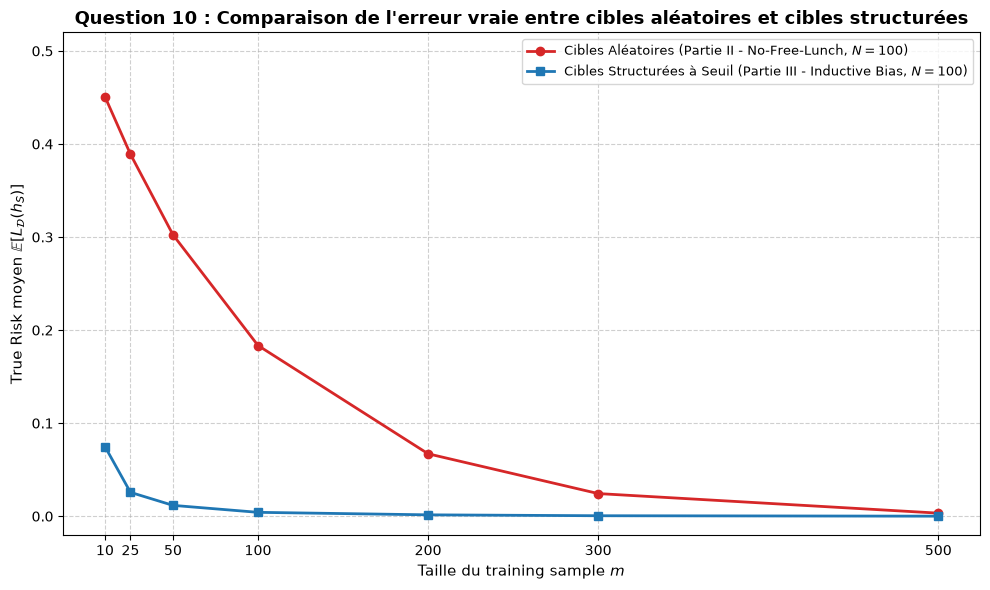

In [14]:
# Visualisation comparative : Cibles aléatoires (Partie II) vs Cibles structurées à seuil (Partie III)
plt.figure(figsize=(10, 6))

# Courbe 1 : Cibles aléatoires avec mémorisation (N = 100)
plt.plot(
    m_tab_nfl,
    exp_0,
    marker='o',
    linestyle='-',
    color='tab:red',
    linewidth=2,
    label='Cibles Aléatoires (Partie II - No-Free-Lunch, $N=100$)',
)

# Courbe 2 : Cibles structurées à seuil avec ERM (N = 100)
risques_q9_list = [resultats_q9[m] for m in m_tab_p3]
plt.plot(
    m_tab_p3,
    risques_q9_list,
    marker='s',
    linestyle='-',
    color='tab:blue',
    linewidth=2,
    label=(
        'Cibles Structurées à Seuil (Partie III - Inductive Bias,'
        ' $N=100$)'
    ),
)

plt.title(
    'Question 10 : Comparaison de l\'erreur vraie entre cibles aléatoires et'
    ' cibles structurées',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel(r'Taille du training sample $m$', fontsize=11)
plt.ylabel(r'True Risk moyen $\mathbb{E}[L_\mathcal{D}(h_S)]$', fontsize=11)
plt.xticks(m_tab_p3)
plt.ylim(-0.02, 0.52)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9.5, loc='upper right')
plt.tight_layout()
plt.show()

### Réponse Question 10 : Random Targets vs. Structured Targets

**1. Comparaison visuelle et comportementale :**
   * Fonctions cibles aléatoires (Courbe rouge) : L'erreur vraie reste durablement élevée (ou diminue très lentement uniquement à mesure que $m$ se rapproche de $N$). Comme il n'y a aucune structure logique entre les points, l'algorithme est incapable de généraliser : il ne fait que de la mémorisation.
   * Fonctions cibles structurées à Seuil (Courbe bleue) : L'erreur vraie chute rapidement vers $0$ dès que $m$ augmente à peine. L'algorithme tire profit de l'échantillon d'entraînement pour trouver la règle (le seuil $\theta$).

**2. Le rôle effectivement important de l'Inductive Bias :**
   * Cette comparaison illustre parfaitement pourquoi le théorème du *No-Free-Lunch* ne contredit pas la réalité du Machine Learning. Le NFL s'applique aux fonctions cibles totalement arbitraires et sans structure. 
   * En pratique, les problèmes réels possèdent une structure sous-jacente (régularité, linéarité, seuils, etc.). En choisissant une classe d'hypothèses $\mathcal{H}$ qui correspond à cette structure, donc en introduisant une inductive bias : on exclut une infinité de fonctions fausses, ce qui permet à l'algorithme d'avoir une sample complexity faible et de généraliser avec succès sur des exemples totalement inédits.

## 11. Final Analysis

- **Concentration du risque empirique ($L_S(h)$) autour du true risk :** 
  Le risque empirique est une moyenne de variables aléatoires i.i.d. dont l'espérance mathématique est rigoureusement égale au true risk (estimateur sans biais). D'après l'inégalité de Hoeffding, la probabilité d'un large écart entre le risque empirique et le vrai risque décroît exponentiellement avec la taille de l'échantillon $m$. Lorsque $m$ augmente, la variance diminue, ce qui concentre fortement la distribution de $L_S(h)$ autour de $L_D(h)$

- **Nécessité du contrôle simultané (Convergence Uniforme) :** 
  Puisque l'algorithme d'apprentissage par minimisation du risque empirique (ERM) choisit son hypothèse $h_S$ en fonction des données observées dans le sample $S$, on ne peut pas anticiper à l'avance quel modèle spécifique sera retenu. Pour garantir que ce modèle généralise bien, l'approximation entre l'empirical error et le true risk doit être vrai simultanément pour l'ensemble des hypothèses de la classe H (notion d'échantillon epsilon-représentatif).

- **Impact de la taille de la classe d'hypothèses H :** 
  Augmenter la complexité ou la taille de H accroît le nombre d'hypothèses h candidats potentiels. Par la borne de l'union (union bound), la probabilité qu'au moins une "mauvaise" hypothèse apparaisse parfaite (alors qu'en réalité elle est fausse) sur l'échantillon d'entraînement augmente. Par conséquent, un espace d'hypothèses plus riche exige davantage de données d'entraînement pour maintenir un même niveau de garantie de généralisation.

- **Caractère conservative des bornes théoriques :** 
  Les bornes découlant de l'inégalité de Hoeffding et de la borne de l'union sont par nature conservative car elles doivent être vraies pour les pires scénarios possibles, quelles que soient la distribution et la structure des données. Elles ne sont donc que des conditions suffisantes pour garantir la convergence, mais ne reflètent pas nécessairement le minimum exact d'exemples requis en pratique.

- **Why completely random targets make unseen labels unpredictable :** 
  Dans le cas de fonctions cibles générées par des tirages de Bernoulli indépendants pour chaque point du domaine, il n'existe aucun lien logique ou régularité entre les entrées parce qu'elles sont indépendantes. Connaître l'étiquette d'un point observé n'apporte strictement aucune information sur la valeur d'une entrée jamais vue (unseen input).

- **Démonstration par le No-Free-Lunch (NFL) :** 
  L'expérience NFL de la Partie II démontre que si on n'a pas d'inductive bias, une fraction non négligeable du domaine d'entrée reste unseen après l'entraînement. Sur ces unseen input, l'algorithme de mémorisation commet en moyenne 50 pour cent d'erreurs, ce qui empêche toute généralisation fiable à partir des données seules, et ce même si la tâche admet un prédicteur parfait.

- **How restricting the target and hypothesis classes to thresholds introduces prior knowledge :** 
  Restreindre la classe cible et la classe d'hypothèses à des structures géométriques spécifiques (comme que les fonctions à seuil) permet d'appliquer un inductive bias. On suppose ainsi que les données suivent une règle géométrique claire plutôt que de chercher au hasard.

- **Généralisation efficace grâce à l'inductive Bias :** 
  Grâce à cet alignement entre la structure de la cible et la classe d'hypothèses, l'algorithme ERM n'a plus besoin de mémoriser individuellement chaque point du domaine. Il lui suffit d'observer un nombre suffisant d'exemples pour localiser et estimer la position du seuil, ce qui baisse énormément la sample complexity et permet de généraliser avec succès sur des données unseen.

### Conclusion générale :

* Pour conclure, la convergence uniforme assure que le risque empirique se concentre vers le true risk, en contrôlant simultanément toutes les hypothèses de H malgré des bornes théoriques parfois conservatrices. Quand on a des fonctions cibles aléatoires, le théorème du No-Free-Lunch démontre qu'aucun learner ne peut prédire des labels unseen seulement à partir des données d'entraînement. L'utilisation d'un biais inductif, tel que les classifieurs à seuil, introduit les connaissances a priori indispensables pour permettre au modèle de généraliser au-delà des exemples observés.

---
Note : Ce travail a été réalisé avec l'aide de l'IA générative Gemini comme outil d'assistance.